<a href="https://colab.research.google.com/github/Eli39603/insurance-claims-ml/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Car Insurance Claim Costs
### Machine Learning final project

In this project we predict how much each driver will cost the insurance company in claims per year.

In [3]:
# 2-a Load the data
from google.colab import drive
drive.mount('/content/drive')

# All imports for the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

# Load the data
path = '/content/drive/MyDrive/פרויקט - למידת מכונה/dataset_class.csv'
dataset = pd.read_csv(path)

print(dataset.shape)
dataset.head()

Mounted at /content/drive
(45000, 30)


,customer_id_hash,agent_code,country,area_type,region_density,winter_severity,driver_age,gender,marital_status,license_years,...,annual_km_estimated,pct_intercity,pct_night_driving,parking_type,current_premium,claim_count,at_fault,days_to_settlement,police_report_filed,annual_claim_cost
0,6db089eb,A043,ES,suburban,855,1.3,75,F,widowed,54,...,7500.0,5,15,lot,4450,1,0.0,27.0,0.0,6178
1,d3a860d7,A057,GB,suburban,1225,2.7,76,M,married,45,...,3000.0,25,10,street,1630,0,NaN,NaN,NaN,0
2,f0610253,A186,IL,suburban,1651,1.9,60,M,single,42,...,12500.0,0,5,garage,980,0,NaN,NaN,NaN,0
3,3137c022,A002,JP,urban,5441,7.7,55,M,divorced,34,...,10000.0,5,5,street,1810,0,NaN,NaN,NaN,0
4,a1513621,A028,FR,urban,3231,5.9,69,M,widowed,51,...,NaN,5,40,street,12290,0,NaN,NaN,NaN,0


### 2. Input data

**2-a** We loaded the file from Google Drive. It has 45,000 drivers and 30 columns.

### 2.2 Data Leakage Analysis

To predict `annual_claim_cost` for a **new** policy, we must exclude any fields that are only known **after** a claim is filed or during the policy term.

**Fields to drop (Leakage & Identifiers):**
* `customer_id_hash`: Unique identifier (no predictive power, can cause overfitting).
* `claim_count`: Future information (known only after the policy term starts).
* `at_fault`: Post-accident detail.
* `days_to_settlement`: Post-accident detail.
* `police_report_filed`: Post-accident detail.
* `annual_claim_cost`: The target variable itself.
* **`current_premium`:** In standard insurance, the `current_premium` is calculated and paid **upfront** at policy inception. Because it is known at the time of issuing a new policy, it does not violate leakage rules. We decided to drop it because we are trying to build an unbiased, independent "pure premium" risk model from raw driver behaviors, without letting the existing premium framework influence the predictions.

> ⚠️ **To review (current_premium):** the data dictionary says this is the premium paid at the **end** of the policy year, so it is not known when a new policy starts. Suggested wording: *"According to the data dictionary, this is the premium paid at the end of the policy year. It is not known when a new policy starts, so using it would be data leakage."*

### 2.3 Data exploration

**2.3-a Column types and missing values**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id_hash       45000 non-null  object 
 1   agent_code             45000 non-null  object 
 2   country                45000 non-null  object 
 3   area_type              45000 non-null  object 
 4   region_density         45000 non-null  int64  
 5   winter_severity        45000 non-null  float64
 6   driver_age             45000 non-null  int64  
 7   gender                 45000 non-null  object 
 8   marital_status         45000 non-null  object 
 9   license_years          45000 non-null  int64  
 10  prior_claims_5y        41858 non-null  float64
 11  no_claims_years        45000 non-null  int64  
 12  violations_3y          45000 non-null  int64  
 13  vehicle_type           45000 non-null  object 
 14  vehicle_age            45000 non-null  int64  
 15  en

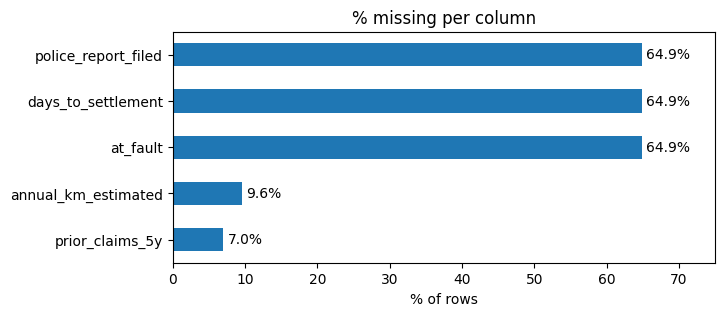

at_fault missing  False  True 
cost is 0                     
False             15793      0
True                  0  29207


In [7]:
# 2.3-a Column types and missing values
dataset.info()

missing = dataset.isna().mean() * 100
missing = missing[missing > 0].sort_values()
print(missing.sort_values(ascending=False).round(2))

ax = missing.plot(kind='barh', figsize=(7, 3), title='% missing per column')
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
ax.set_xlabel('% of rows')
ax.set_xlim(0, 75)
plt.show()

# Is at_fault missing exactly for the drivers with 0 cost?
print(pd.crosstab(dataset['annual_claim_cost'] == 0,
                  dataset['at_fault'].isna(),
                  rownames=['cost is 0'], colnames=['at_fault missing']))

* `at_fault`, `police_report_filed` and `days_to_settlement` are missing in 64.9% of the rows. `at_fault` is missing exactly for the 29,207 drivers whose cost is 0, and it is not missing for any driver with a cost above 0. Either way, these are leakage columns and we will drop them (see 2.2).
* `annual_km_estimated` is missing in 9.6% of the rows and `prior_claims_5y` in 7.0%. We will fill them in, after checking whether the missing values follow a pattern.
* `vehicle_value` is stored as text and not as a number. We will check why.

**2.3-b Summary statistics**

We look at the range and the mean of each numeric column, to spot values that do not make sense.

In [9]:
# 2.3-b Summary statistics for the numeric columns
print(dataset.describe())

# annual_km_estimated: how many rows are 999,999, and what is the next highest value?
km = dataset['annual_km_estimated']
print('Rows with 999,999:', (km == 999999).sum())
print('Highest values other than 999,999:')
print(km[km != 999999].nlargest(5))

# license_years: in how many rows is it impossible compared to the driver's age?
too_long = dataset['license_years'] > dataset['driver_age'] - 16
print('Rows where license_years > driver_age - 16:', too_long.sum())
print(dataset.loc[too_long, ['driver_age', 'license_years']].head())

       region_density  winter_severity    driver_age  license_years  \
count    45000.000000     45000.000000  45000.000000   45000.000000   
mean      1886.716311         3.459389     48.010511      28.853867   
std       2161.133202         2.214855     16.613355      16.866459   
min          4.000000         0.000000     18.000000       0.000000   
25%        498.000000         1.700000     35.000000      15.000000   
50%       1151.000000         3.300000     47.000000      28.000000   
75%       2593.000000         5.000000     60.000000      41.000000   
max      20000.000000        10.000000     90.000000      95.000000   

       prior_claims_5y  no_claims_years  violations_3y   vehicle_age  \
count     41858.000000     45000.000000   45000.000000  45000.000000   
mean          1.039706         6.750933       0.416467      7.638844   
std           1.384058         8.101940       0.717039      5.313188   
min           0.000000         0.000000       0.000000      0.000000   


**Suspicious values to check later:**
* `license_years` goes up to 95, but the oldest driver is 90. In 153 rows the license years are greater than the age minus 16, and in some of them even greater than the age itself (for example age 30 with 33 license years).
* `annual_km_estimated` has 1,386 rows with exactly 999,999. The next highest value is 120,000, with no values in between. 999,999 km a year is about 2,740 km a day, which is not a possible value.
* `has_telematics` has the value 2, but according to the data dictionary the values are only 1 (yes) or 0 (no).
* The count of `prior_claims_5y` is 41,858, below 45,000, which matches the missing values we saw in 2.3-a.
* `vehicle_value` does not appear in the table, because it is stored as text.

**2.3-c Why is vehicle_value stored as text?**

In 2.3-a we saw that `vehicle_value` is stored as text, although it should be a number. Before cleaning it, we check what the problem is.

In [8]:
# 2.3-c Why is vehicle_value stored as text?
print(dataset['vehicle_value'].head(10))

as_number = pd.to_numeric(dataset['vehicle_value'], errors='coerce')
bad = dataset.loc[as_number.isna() & dataset['vehicle_value'].notna(), 'vehicle_value']
print('Values that are not numbers:', len(bad))
print(bad.value_counts().head(20))

still_bad = pd.to_numeric(bad.str.replace(',', ''), errors='coerce').isna().sum()
print('Still not numbers after removing commas:', still_bad)

0    51000
1    56500
2    19500
3    37500
4    86000
5    47000
6    29000
7    23500
8    43000
9    52000
Name: vehicle_value, dtype: object
Values that are not numbers: 682
vehicle_value
22,000    11
9,500     10
32,000     9
27,500     8
28,500     8
41,000     8
13,500     8
48,000     7
7,500      7
49,500     7
8,000      7
26,000     7
13,000     6
28,000     6
9,000      6
20,000     6
20,500     6
30,500     6
8,500      6
23,500     6
Name: count, dtype: int64
Still not numbers after removing commas: 0


* 682 values (1.5%) have a thousands comma, for example "22,000". This was enough to make the whole column text.
* After removing the comma, all values turn into numbers, so there is no other problem.
* In the cleaning step we will remove the comma and convert the column to numbers.

**2.3-d Distribution of annual_claim_cost**

This is the variable the model predicts. In 2.3-b we saw that its median is 0 and its maximum is 224,808, so we check how it is distributed, because this affects the choice of model and metrics.

Mean: 3051
Median: 0.0
Drivers with 0 cost: 64.9 %
Drivers above 10,000: 9.2 %


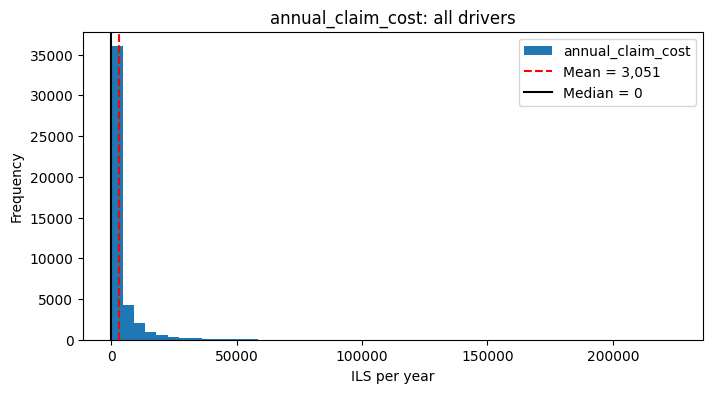

In [5]:
# 2.3-d Distribution of the target: annual_claim_cost
cost = dataset['annual_claim_cost']
print('Mean:', round(cost.mean()))
print('Median:', cost.median())
print('Drivers with 0 cost:', round((cost == 0).mean() * 100, 1), '%')
print('Drivers above 10,000:', round((cost > 10000).mean() * 100, 1), '%')

ax = cost.plot(kind='hist', bins=50, figsize=(8, 4), title='annual_claim_cost: all drivers')
ax.axvline(cost.mean(), color='red', linestyle='--', label=f'Mean = {cost.mean():,.0f}')
ax.axvline(cost.median(), color='black', label=f'Median = {cost.median():,.0f}')
ax.set_xlabel('ILS per year')
ax.legend()
plt.show()

* The mean is 3,051 ILS and the median is 0.
* 64.9% of the drivers have a cost of 0, and 9.2% cost more than 10,000 ILS.
* In the chart, almost all drivers are in the first bar, near 0, with a long thin tail up to 224,808 ILS.

**2.3-e Cost of drivers with a claim**

In the previous chart almost all drivers are squeezed near 0, so we cannot see how the cost is spread. So we look only at drivers with a claim, on a log scale. On this scale each step of 1 on the axis means 10 times the cost, so both small and very large costs fit in the same chart.

Drivers with a claim: 15793
Mean: 8693
Median: 5359.0
Smallest cost: 600
Most common values:
annual_claim_cost
600     163
1200     37
1800     16
3512      9
1565      8
Name: count, dtype: int64


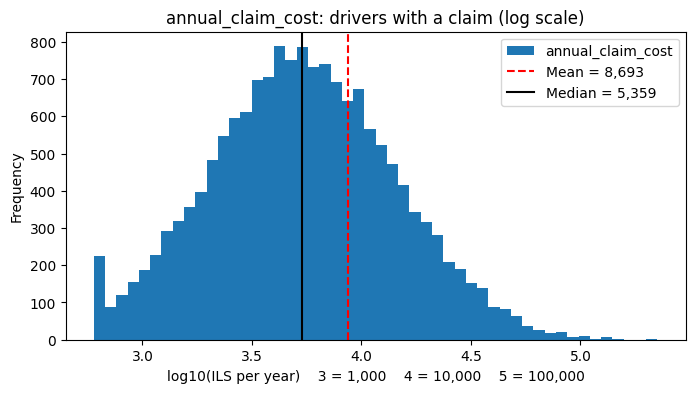

In [6]:
# 2.3-e Cost of drivers with a claim (log scale)
claims = cost[cost > 0]
print('Drivers with a claim:', len(claims))
print('Mean:', round(claims.mean()))
print('Median:', claims.median())
print('Smallest cost:', claims.min())
print('Most common values:')
print(claims.value_counts().head(5))

ax = np.log10(claims).plot(kind='hist', bins=50, figsize=(8, 4),
                           title='annual_claim_cost: drivers with a claim (log scale)')
ax.axvline(np.log10(claims.mean()), color='red', linestyle='--', label=f'Mean = {claims.mean():,.0f}')
ax.axvline(np.log10(claims.median()), color='black', label=f'Median = {claims.median():,.0f}')
ax.set_xlabel('log10(ILS per year)    3 = 1,000    4 = 10,000    5 = 100,000')
ax.legend()
plt.show()

* 15,793 drivers had a cost above 0.
* For them, the mean is 8,693 ILS and the median is 5,359 ILS.
* On the log scale the chart looks like a bell.
* The lowest cost is 600 ILS, and 163 drivers have a cost of exactly 600. The next most common values are 1,200 (37 drivers) and 1,800 (16 drivers).

### 3. Models: draft from the 2.2 work (needs review later)

**Note:** this code and the text below it were added as-is from the partner's notebook. They belong to section 3 and still need review and fixes before we use them.

In [ ]:
# 3-a Split X and y
# Separate features and target while preventing data leakage
# use this in prepare_data func

leakage_and_id_cols = [
    'customer_id_hash',
    'claim_count',
    'at_fault',
    'days_to_settlement',
    'police_report_filed',
    'current_premium'
]

target_col = 'annual_claim_cost'

# Features (X) and Target (y)
X = dataset.drop(columns=leakage_and_id_cols + [target_col])
y = dataset[target_col]

print("Features available for training (excluding leakages):")
print(list(X.columns))
print(X)
print(y)

Features available for training (excluding leakages):
['agent_code', 'country', 'area_type', 'region_density', 'winter_severity', 'driver_age', 'gender', 'marital_status', 'license_years', 'prior_claims_5y', 'no_claims_years', 'violations_3y', 'vehicle_type', 'vehicle_age', 'engine_hp', 'vehicle_value', 'safety_features_count', 'has_telematics', 'usage_type', 'annual_km_estimated', 'pct_intercity', 'pct_night_driving', 'parking_type']
      agent_code country area_type  region_density  winter_severity  \
0           A043      ES  suburban             855              1.3   
1           A057      GB  suburban            1225              2.7   
2           A186      IL  suburban            1651              1.9   
3           A002      JP     urban            5441              7.7   
4           A028      FR     urban            3231              5.9   
...          ...     ...       ...             ...              ...   
44995       A011      ES  suburban             747              

In [ ]:
# 3-b Polynomial model (draft)
# preventing Data leakage in pipeline cross validation
# (imports moved to the first cell)

# ŷ = w0 + w1x + w2x2 + … + wdxd
# w0 … wd   coefficients, learned from the data by least squares
# x, x2, …, xd   features, computed from age before fitting
# d   degree, chosen by us: a hyperparameter
# d = 1: a line    d = 2: a parabola     d = 3: a cubic


def poly_model(d):
    return make_pipeline(
        PolynomialFeatures(d, include_bias=False),
        StandardScaler(), LinearRegression())

# 1) lock away 20% as the test set
X_tv, X_test, y_tv, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)
# 2) split the rest: 75% train, 25% validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tv, y_tv, test_size=0.25, random_state=0)

val_rmse = {}

for d in range(1, 9):
    model = poly_model(d).fit(X_tr, y_tr)
y_hat = model.predict(X_val)
val_rmse[d] = root_mean_squared_error(y_val, y_hat)
best_d = min(val_rmse, key=val_rmse.get)
print(best_d)


cv = KFold(n_splits=5, shuffle=True, random_state=0)

model = make_pipeline(
    PolynomialFeatures(d),
    StandardScaler(),
    LinearRegression()
)
cross_val_score(model, X, y, cv=cv)


ValueError: could not convert string to float: 'A013'

We use fit_transform(X_train) to compute the mean and standard deviation only from the training set, and then scale it.
We then use transform(X_test) on the test set. This ensures that no information from the test set (like its mean or range) leaks into the training phase (preventing data leakage).
* **The Pipeline .fit() on the Training Fold (No Leakage!):**
PolynomialFeatures learns the feature structure of the training fold and transforms it.
StandardScaler calculates the mean $(\mu)$ and standard deviation $(\sigma)$ strictly from this training fold only, and scales it.
LinearRegression fits its weights using this scaled training data.
* **The Pipeline .predict() / .score() on the Validation Fold:**
PolynomialFeatures transforms the validation fold.
StandardScaler transforms the validation fold using the $(\mu)$ and $(\sigma)$ calculated earlier from the training fold (it does not recalculate mean/std on the validation fold).
LinearRegression predicts the outcomes for the validation fold and calculates the score (by default, $R^2$$R^2$ score for regression).